# Comparing two processing chains' size distributions, in dB

**Two products of the same cloud, from two processing chains, rarely agree second by second, and a ratio
quoted without the steps below mixes a real processing difference with a timing artefact or one bad
second.** This notebook builds two synthetic products with a known 1.5 dB offset in the small bins, breaks
them the way real per-second files break (one infinite second, one duplicated second, a 2 s clock lag),
and recovers the offset.

**What you get**

- a common time axis, with non-finite and duplicated seconds dropped and the reason for each;
- a lag scan, and leg composites (means over a cloud leg) instead of second-by-second ratios when the best lag is small;
- differences in dB per size bin and in total concentration;
- attribution by switching one processing choice at a time: sample area, acceptance rules, shattering treatment.

> **Every number in this notebook is synthetic**, drawn from a fixed-seed random-number generator in section 1; no data file is read.

**Related work.** The same procedure applies to any pair of open chains: this package's engines, or NCAR's
`process2d` (GitHub repository `NCAR/aircraft_oap`), among others. Nothing here depends on which chain wrote
which file.

**Before this:** [06_read_products](../1_getting_started/06_read_products.ipynb) (Reading the output files). **Related:** [01_validate_against_a_product](../3_validation/01_validate_against_a_product.ipynb). **Needs:** the enhancements package and `pip install "arrayprobe[extra]"` (matplotlib).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/7_analysis_and_outputs/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

## 1. Two synthetic products of one cloud

Both chains see the same lognormal cloud (geometric mean diameter 20 µm, width 1.5, 100 cm⁻³ at leg
centre), broken up the way a real leg is: clear-air gaps with sharp cloud edges, and second-to-second
patchiness inside cloud. Chain B reads the bins below 50 µm 1.5 dB high, as a different sample-area rule would. Each
second gets independent Poisson counting noise, and chain B's clock runs 2 s late.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(20261005)
edges = np.geomspace(10, 1000, 31)            # µm
mid = np.sqrt(edges[:-1] * edges[1:])
dlogd = np.diff(np.log10(edges))

def lognormal_dndlogd(n_tot, dg=20.0, sg=1.5):
    s = np.log10(sg)
    return n_tot / (np.sqrt(2 * np.pi) * s) * np.exp(-0.5 * (np.log10(mid / dg) / s) ** 2)

t = np.arange(600)                            # seconds of one leg
smooth = 100 * np.exp(-0.5 * ((t - 300) / 150) ** 2)     # cm^-3, the leg-scale shape
patchy = np.exp(0.4 * rng.standard_normal(t.size))      # per-second patchiness inside cloud
in_cloud = np.ones(t.size)
for start in rng.choice(np.arange(20, 580), size=8, replace=False):
    in_cloud[start:start + rng.integers(3, 12)] = 0.02  # clear-air gaps with sharp edges
envelope = smooth * patchy * in_cloud
volume = 5.0                                  # cm^3 sampled per second, both chains
truth = np.array([lognormal_dndlogd(n) for n in envelope])          # (time, bin), per dlogD

TRUE_OFFSET_DB = 1.5
gain_b = np.where(mid < 50, 10 ** (TRUE_OFFSET_DB / 10), 1.0)

def observe(expected):
    counts = rng.poisson(expected * dlogd * volume)
    return counts / (volume * dlogd)

LAG_B = 2
a = observe(truth)
b = observe(np.roll(truth, LAG_B, axis=0) * gain_b)      # chain B's clock is 2 s late
time_a, time_b = t.copy(), t.copy()
print(a.shape, b.shape, f"true small-bin offset {TRUE_OFFSET_DB} dB, true lag {LAG_B} s")

(600, 30) (600, 30) true small-bin offset 1.5 dB, true lag 2 s


## 2. Break chain B the way real files break

- **An infinite second.** A 1-s overload or dead-time spike can leave a chain's sample volume at zero for
  that second; counts over a zero volume give `inf` (or `nan` for 0/0), and one such second turns any mean
  over the leg into `inf`.
- **A duplicated second.** Timing jitter at a record or file boundary can stamp two rows with one second;
  keeping both double-weights that second and shifts every row after it by one if the series is aligned
  by position (notebook 27 covers the duplicate itself).

In [3]:
b[200] = np.inf                                # second 200: zero sample volume
dup = 350
time_b = np.insert(time_b, dup, time_b[dup])    # second 350 stamped twice
b = np.insert(b, dup, b[dup] * 1.3, axis=0)     # with a different value in the copy
print("chain B rows:", len(time_b), " distinct seconds:", len(np.unique(time_b)))
print("naive mean of chain B total N:", np.mean((b * dlogd).sum(axis=1)))

chain B rows: 601  distinct seconds: 600
naive mean of chain B total N: inf


## 3. A common time axis

Drop non-finite seconds and duplicated seconds from **both** products (a duplicate cannot be resolved
without knowing which copy the chain meant, so neither copy is used), then keep the seconds both carry.
Align by timestamp, never by row position.

In [4]:
def clean(time, psd):
    finite = np.all(np.isfinite(psd), axis=1)
    uniq, counts = np.unique(time, return_counts=True)
    duplicated = np.isin(time, uniq[counts > 1])
    keep = finite & ~duplicated
    print(f"  dropped {np.sum(~finite)} non-finite and {np.sum(duplicated)} duplicated rows")
    return time[keep], psd[keep]

print("chain A:"); ta, pa = clean(time_a, a)
print("chain B:"); tb, pb = clean(time_b, b)
common = np.intersect1d(ta, tb)
pa_c = pa[np.searchsorted(ta, common)]
pb_c = pb[np.searchsorted(tb, common)]
print("common seconds:", len(common))

chain A:
  dropped 0 non-finite and 0 duplicated rows
chain B:
  dropped 1 non-finite and 2 duplicated rows
common seconds: 598


## 4. Lag scan

Correlate the two total-concentration series over a range of shifts. The scan can only find a lag if the series
has features sharper than the lag: cloud edges, gaps, second-to-second patchiness. A smooth leg-scale
curve changes so little in 2 s that a 1 s and a 2 s shift correlate almost equally, and counting
noise then decides the winner (with this section's leg built from the smooth curve alone, the scan
reports 1 s). On real data, scan a stretch with edges, not the middle of a uniform layer. A best lag of a few seconds
(10 s or less) is ordinary timing jitter between chains; above that it is a systematic timing problem
to find and fix before any comparison (notebook 21).

In [5]:
def total(psd):
    return (psd * dlogd).sum(axis=1)

na, nb = total(pa_c), total(pb_c)
lags = np.arange(-10, 11)
def corr_at(lag):
    if lag >= 0:
        x, y = na[:len(na) - lag], nb[lag:]
    else:
        x, y = na[-lag:], nb[:len(nb) + lag]
    return np.corrcoef(x, y)[0, 1]
r = np.array([corr_at(k) for k in lags])
best = int(lags[np.argmax(r)])
print(f"best lag {best} s (r = {r.max():.4f}); true lag {LAG_B} s")

best lag 2 s (r = 0.9914); true lag 2 s


## 5. Leg composites, not second-by-second ratios

With a best lag this small, compare the **mean distribution over the leg** from each chain. Per-second
ratios carry the counting noise of two Poisson draws and the residual timing jitter; the leg mean
averages both away, and the comparison is then a difference in dB:
`ΔdB = 10 log10(N_B / N_A)`.

leg composite, bins < 50 µm: +1.50 dB (true +1.50)
leg composite, total N:      +1.48 dB
per-second total, spread (5-95 %): -3.46 to +6.60 dB


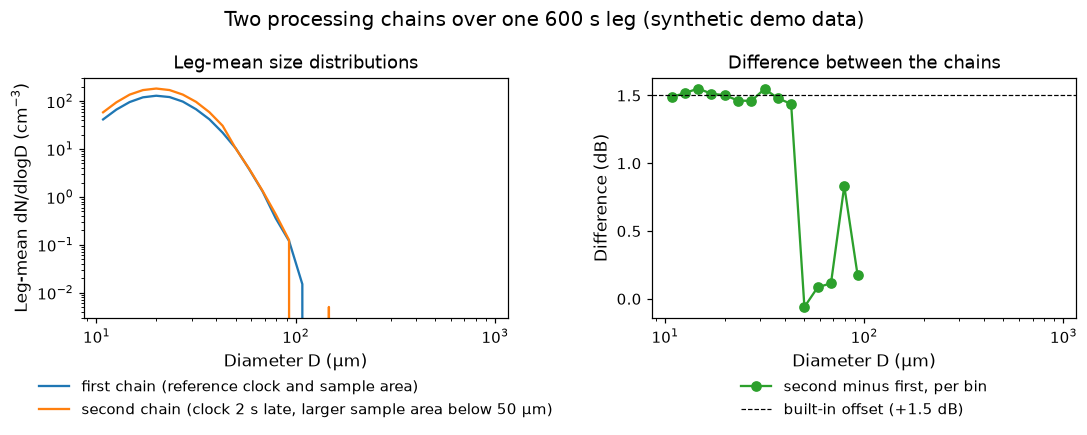

In [6]:
comp_a, comp_b = pa_c.mean(axis=0), pb_c.mean(axis=0)
with np.errstate(divide="ignore", invalid="ignore"):
    db_bin = 10 * np.log10(comp_b / comp_a)
    per_second = 10 * np.log10(nb / na)
db_total = 10 * np.log10((comp_b * dlogd).sum() / (comp_a * dlogd).sum())
small = (mid < 50) & np.isfinite(db_bin)
print(f"leg composite, bins < 50 µm: {np.mean(db_bin[small]):+.2f} dB (true {TRUE_OFFSET_DB:+.2f})")
print(f"leg composite, total N:      {db_total:+.2f} dB")
print(f"per-second total, spread (5-95 %): {np.nanpercentile(per_second, 5):+.2f} to "
      f"{np.nanpercentile(per_second, 95):+.2f} dB")

plt.rcParams.update({"font.size": 10, "legend.fontsize": 10})
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
ax[0].loglog(mid, comp_a, label="first chain (reference clock and sample area)")
ax[0].loglog(mid, comp_b, label="second chain (clock 2 s late, larger sample area below 50 µm)")
ax[0].set_xlabel("Diameter D (µm)"); ax[0].set_ylabel("Leg-mean dN/dlogD (cm$^{-3}$)")
ax[0].set_title("Leg-mean size distributions")
ax[1].semilogx(mid, db_bin, "o-", c="C2", label="second minus first, per bin")
ax[1].axhline(TRUE_OFFSET_DB, ls="--", c="k", lw=0.8, label=f"built-in offset ({TRUE_OFFSET_DB:+.1f} dB)")
ax[1].set_xlim(ax[0].get_xlim())
ax[1].set_xlabel("Diameter D (µm)"); ax[1].set_ylabel("Difference (dB)")
ax[1].set_title("Difference between the chains")
for a_ in ax:
    a_.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
fig.suptitle("Two processing chains over one 600 s leg (synthetic demo data)")
fig.tight_layout(); plt.show()


*Figure 1. Left: the leg-mean size distribution from each synthetic chain. Right: their per-bin difference in dB; the dashed line is the offset built into the second chain's sample area below 50 µm, and bins above 50 µm scatter within 1 dB of 0 dB with counting noise, large particles being rare. Bins with no counts in either chain are not drawn.*

## 6. Attribute the difference by switching one choice at a time

A difference between chains is the sum of several processing choices. Re-run one chain with exactly
one choice changed to the other chain's, and measure what moves. Below, three toy choices each act on
chain A's leg composite: a sample-area rule (scales the small bins), an acceptance rule (removes a
fraction of large images) and a shattering treatment (removes small particles that arrive in bursts).
Only the switch that closes the gap names the cause; the others move it little or not at all.

In [7]:
choices = {
    "sample area (B's rule)": lambda p: p * gain_b,
    "acceptance (B's rule)": lambda p: p * np.where(mid > 300, 0.9, 1.0),
    "shattering (B's rule)": lambda p: p * np.where(mid < 15, 0.97, 1.0),
}
base = np.mean(db_bin[small])
for name, apply in choices.items():
    with np.errstate(divide="ignore", invalid="ignore"):
        moved = 10 * np.log10(comp_b / apply(comp_a))
    print(f"{name:24s} small-bin gap {base:+.2f} -> {np.mean(moved[small]):+.2f} dB")

sample area (B's rule)   small-bin gap +1.50 -> -0.00 dB
acceptance (B's rule)    small-bin gap +1.50 -> +1.50 dB
shattering (B's rule)    small-bin gap +1.50 -> +1.54 dB


In this synthetic case the sample-area switch closes the gap and the other two barely move it,
because the offset was built into the sample area. With real chains, run each switch through the chain
itself (its configuration file or option), never by rescaling its output, and record which switch was
on in the run's own provenance.

## Use it on your own files

Load each product's per-second size distribution as a `(time, bin)` array on the same bin edges, with
its time column, and run sections 3 to 5 unchanged. Rebin first if the two chains' edges differ.

---

## Comparing two products over a cloud leg, in dB

Two products of the same cloud rarely agree second by second: a small clock offset or a different
sample volume scatters the per-second ratio even when the products agree on average. This notebook
compares two size distributions the robust way. It integrates each into a sixth moment with
`arrayprobe_enhancements.analysis.moment`, reports it in dBZ, averages each product over the leg
with `leg_mean` before comparing (a composite), and quotes every difference in dB rather than as a
linear ratio. It runs in seconds on seeded random distributions and needs no data files.

## 1. Two synthetic products of one leg

Product B sees the same cloud as product A, one second later and with 2 dB more sixth moment
(a factor of $10^{0.2}$ in concentration), and both carry independent Poisson counting noise.

In [8]:
import numpy as np
from arrayprobe_enhancements.analysis import leg_mean, moment

rng = np.random.default_rng(45)
edges_mm = np.geomspace(0.01, 1.5, 41)            # 40 explicit bins
mid_mm, dD_mm = 0.5 * (edges_mm[:-1] + edges_mm[1:]), np.diff(edges_mm)
n_sec, lag_s, offset_db = 120, 1, 2.0

shape = np.exp(-mid_mm / 0.15)                     # a fixed size spectrum
amp = 1.0 + 0.8 * np.sin(np.arange(n_sec + lag_s) / 9.0) ** 2   # the cloud varies along the leg
sample_cm3 = 50.0 * dD_mm / 10.0                  # counts -> density per cm^4 (sample volume x width)

def product(amplitude, gain):
    expected = 400.0 * gain * amplitude[:, None] * shape[None, :]
    return rng.poisson(expected) / sample_cm3      # (time, bin) density, cm-4

conc_a = product(amp[lag_s:], 1.0)
conc_b = product(amp[:-lag_s], 10 ** (offset_db / 10))
print(conc_a.shape, conc_b.shape)

(120, 40) (120, 40)


## 2. Sixth moment in dBZ

`moment` integrates over the bin widths; with diameters in millimetres and densities per cm$^4$, the
sixth moment is in mm$^6$ cm$^{-3}$, so a factor of $10^6$ gives $Z$ in mm$^6$ m$^{-3}$, and $10\log_{10}$ gives dBZ.

In [9]:
def dbz(conc):
    z = moment(mid_mm, dD_mm, conc, order=6) * 1e6           # mm^6 m^-3
    with np.errstate(divide="ignore"):
        return 10.0 * np.log10(z)

dbz_a, dbz_b = dbz(conc_a), dbz(conc_b)
print(f"A: {np.nanmin(dbz_a):.2f} to {np.nanmax(dbz_a):.2f} dBZ")
print(f"B: {np.nanmin(dbz_b):.2f} to {np.nanmax(dbz_b):.2f} dBZ")

A: 45.70 to 55.01 dBZ
B: 48.31 to 56.68 dBZ


## 3. Second by second against the composite

The per-second difference scatters with counting noise and the lag. The composite averages each
product's Z over the leg first (in linear units, as an average of power must be), then converts
the two means to dBZ and differences them.

In [10]:
per_second_db = dbz_b - dbz_a
z_a = moment(mid_mm, dD_mm, conc_a, order=6) * 1e6
z_b = moment(mid_mm, dD_mm, conc_b, order=6) * 1e6
composite_db = 10 * np.log10(leg_mean(z_b)) - 10 * np.log10(leg_mean(z_a))

print(f"per-second difference: median {np.median(per_second_db):.2f} dB, "
      f"spread (5-95 %) {np.percentile(per_second_db, 5):.2f} to {np.percentile(per_second_db, 95):.2f} dB")
print(f"composite difference over the leg: {composite_db:.2f} dB (built in: {offset_db:.2f} dB)")
assert abs(composite_db - offset_db) < 0.5
assert np.ptp(per_second_db) > abs(composite_db - offset_db)

per-second difference: median 2.24 dB, spread (5-95 %) -2.43 to 5.63 dB
composite difference over the leg: 1.91 dB (built in: 2.00 dB)


## 4. Per-bin comparison of the leg-mean distributions

The same composite applies bin by bin: average each product's (time, bin) density over the leg
with `leg_mean`, then difference in dB. Bins that one product never populated stay `NaN` rather
than becoming an infinite difference.

In [11]:
mean_a, mean_b = leg_mean(conc_a), leg_mean(conc_b)
with np.errstate(divide="ignore", invalid="ignore"):
    per_bin_db = 10 * np.log10(mean_b / mean_a)
per_bin_db[~np.isfinite(per_bin_db)] = np.nan
filled = np.isfinite(per_bin_db)
print(f"{filled.sum()} of {len(per_bin_db)} bins populated in both; "
      f"median per-bin difference {np.nanmedian(per_bin_db[:20]):.2f} dB over the 20 smallest bins")
assert abs(np.nanmedian(per_bin_db[:20]) - offset_db) < 0.5

40 of 40 bins populated in both; median per-bin difference 1.98 dB over the 20 smallest bins


## 5. Restricting the composite to part of the leg

`leg_mean` takes a `start` and `end` second, so a composite can cover only the in-cloud part of a
leg that a caller has already identified.

Half the leg averages half the seconds, so its composite carries more counting noise and lands
further from the built-in offset than the full-leg composite does. Compare composites of
similar length, and report the number of seconds behind each.

In [12]:
first_half = 10 * np.log10(leg_mean(z_b, 0, n_sec // 2)) - 10 * np.log10(leg_mean(z_a, 0, n_sec // 2))
print(f"composite over the first {n_sec // 2} s: {first_half:.2f} dB")
assert abs(first_half - offset_db) < 0.7

composite over the first 60 s: 1.37 dB


## Summary

- `moment(..., order=6)` integrates a per-bin density over its bin widths; times $10^6$ it is $Z$ in
  mm$^6$ m$^{-3}$, reported as dBZ.
- Per-second differences scatter with counting noise and small clock offsets; the leg composite
  (`leg_mean` of linear Z, then dB) recovers the built-in offset.
- Differences between products are quoted in dB, per second, per leg and per bin, never as linear
  ratios; empty bins stay `NaN`.